# 01 - Data exploration
**Question:** what does the raw Olist-style data look like, and what should we worry about before analysing it?

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", palette=["#7C5CFF", "#22D3EE", "#FFB547", "#34E5A1", "#FF5C8A"])
pd.set_option("display.width", 140)
from python.database_loader import Database, run_named_query
from python.data_ingestion import load_raw, data_source
raw = load_raw()
print('source:', data_source())
pd.DataFrame({k: v.shape for k, v in raw.items()}, index=['rows', 'cols']).T

source: synthetic


,rows,cols
customers,22000,5
orders,22000,8
order_items,25470,7
payments,23075,5
reviews,21645,7
products,3500,9
sellers,600,4
geolocation,1620,5
category_translation,22,2


In [2]:
orders = raw['orders']
print(orders.isna().sum())
orders['order_status'].value_counts()

order_id                           0
customer_id                        0
order_status                       0
order_purchase_timestamp           0
order_approved_at                 39
order_delivered_carrier_date     552
order_delivered_customer_date    773
order_estimated_delivery_date      0
dtype: int64


order_status
delivered      21227
shipped          221
canceled         151
unavailable      129
invoiced         111
processing        78
approved          44
created           39
Name: count, dtype: int64

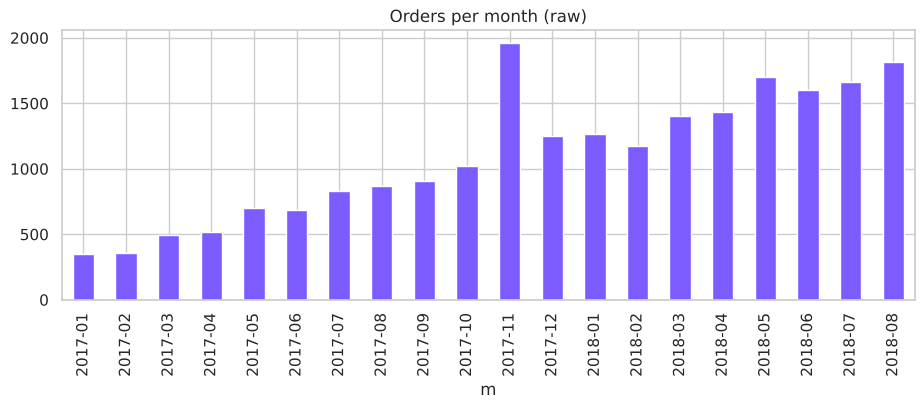

In [3]:
o = orders.assign(m=pd.to_datetime(orders.order_purchase_timestamp).dt.to_period('M').astype(str))
o.groupby('m').size().plot(kind='bar', figsize=(11, 3.5), title='Orders per month (raw)'); plt.show()

**Observations to carry forward:** orders have several statuses (only `delivered` counts as revenue); `customer_id` is per order, so `customer_unique_id` identifies real customers; reviews contain duplicates; some products have no category.